<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Generate the source signals and mix them

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Create time base
np.random.seed(0)
n_samples = 2000
time = np.linspace(0, 8, n_samples)

# Generate three source signals
s1 = np.sin(2 * time)  # Sine wave
s2 = np.sign(np.sin(3 * time))  # Square wave
s3 = signal.sawtooth(2 * np.pi * time)  # Sawtooth wave

S = np.c_[s1, s2, s3]
S += 0.2 * np.random.normal(size=S.shape)  # Add noise
S /= S.std(axis=0)  # Standardize

# Mix data
A = np.array([[1, 1, 1], [0.5, 2, 1.0], [1.5, 1.0, 2.0]])  # Mixing matrix
X = np.dot(S, A.T)  # Mixed signals

### Task 2: Apply FastICA to recover the sources

In [2]:
from sklearn.decomposition import FastICA

ica = FastICA(n_components=3, random_state=0)
S_ica_ = ica.fit_transform(X)  # Reconstruct signals
A_ = ica.mixing_  # Get estimated mixing matrix

### Task 3: Apply PCA to the same mixtures for comparison

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
H = pca.fit_transform(X)  # Reconstruct signals based on orthogonal components

### Task 4: Plot original, mixed, ICA-recovered and PCA-recovered signals

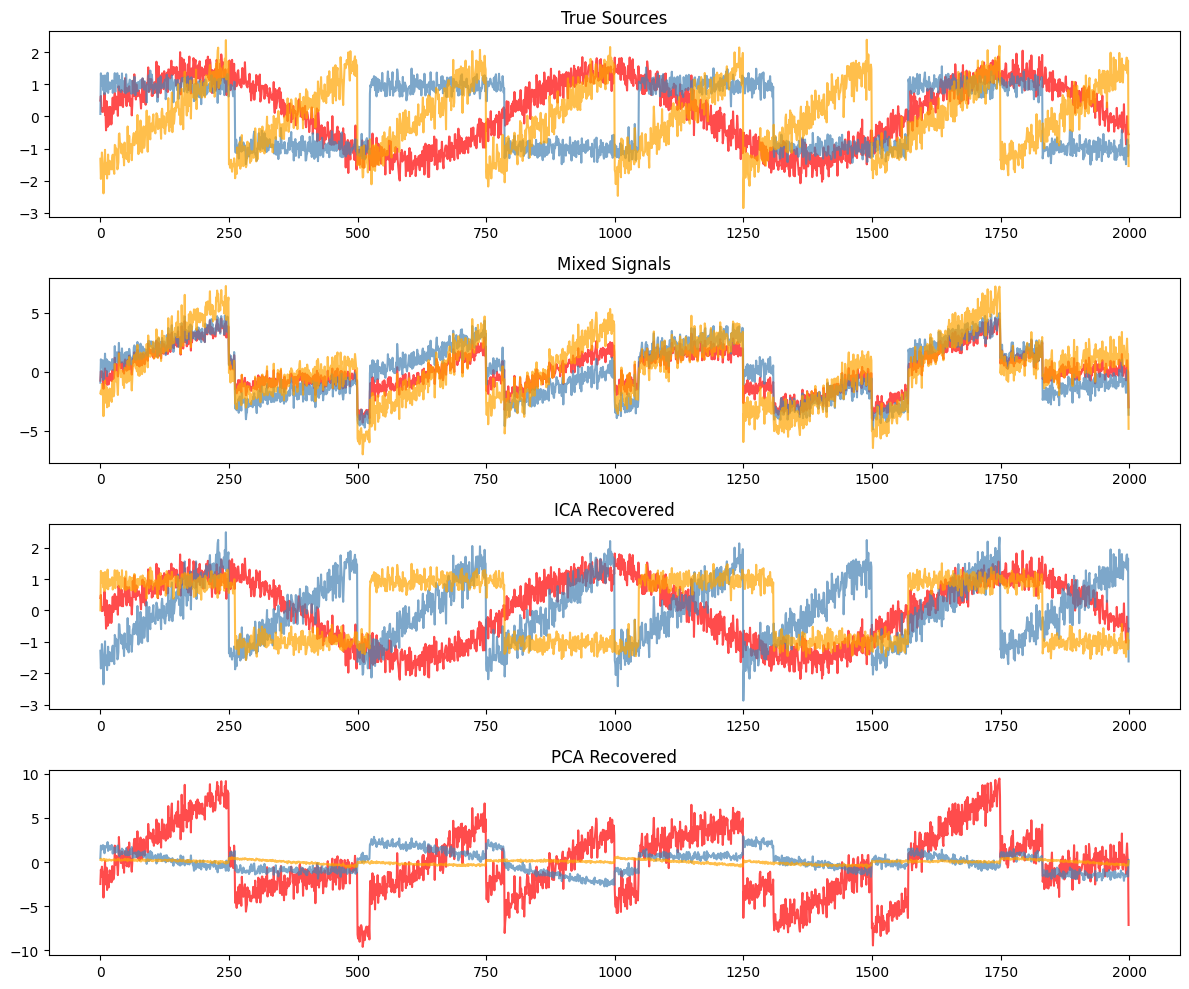

In [4]:
plt.figure(figsize=(12, 10))

models = [S, X, S_ica_, H]
titles = ['True Sources', 'Mixed Signals', 'ICA Recovered', 'PCA Recovered']
colors = ['red', 'steelblue', 'orange', 'green']

for i, (model, title) in enumerate(zip(models, titles)):
    plt.subplot(4, 1, i + 1)
    plt.title(title)
    for sig, color in zip(model.T, colors):
        plt.plot(sig, color=color, alpha=0.7)

plt.tight_layout()
plt.show()

### Task 5: Measure recovery quality with correlation to the true sources

In [5]:
def print_max_correlations(recovered, true_sources, label):
    print(f"--- Max absolute correlation for {label} ---")
    for i in range(true_sources.shape[1]):
        corrs = [abs(np.corrcoef(true_sources[:, i], recovered[:, j])[0, 1]) for j in range(recovered.shape[1])]
        print(f"True Source {i+1} matched max correlation: {max(corrs):.4f}")

print_max_correlations(S_ica_, S, "ICA")
print_max_correlations(H, S, "PCA")

--- Max absolute correlation for ICA ---
True Source 1 matched max correlation: 0.9968
True Source 2 matched max correlation: 0.9996
True Source 3 matched max correlation: 0.9965
--- Max absolute correlation for PCA ---
True Source 1 matched max correlation: 0.7547
True Source 2 matched max correlation: 0.7871
True Source 3 matched max correlation: 0.6709
